# Détection de la dépression chez les étudiants avec TensorFlow

Les troubles dépressifs touchent de nombreux étudiants : pression des études, finances, santé, isolement. Les données collectées par les universités et les enquêtes permettent d'étudier quels facteurs sont associés à la dépression, et si un modèle d'apprentissage profond peut les exploiter.

Nous allons construire un **modèle de classification binaire** avec TensorFlow. Nous verrons :

.Le jeu de données et ses variables

. L'entraînement d'un réseau de neurones pour prédire la dépression (oui / non)

. L'évaluation du modèle, avec un regard critique sur les résultats


In [ ]:
! pip install pandas


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\karel\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [ ]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [3]:
! pip install matplotlib


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\karel\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)
print("TensorFlow :", tf.__version__)
print("Tout fonctionne !")

NumPy : 2.5.4
Pandas : 3.1.0
TensorFlow : 2.21.0
Tout fonctionne !


In [ ]:
import os
import zipfile

from tensorflow.keras import layers
from tensorflow.keras import losses

print(tf.__version__)
print(pd.__version__)

2.21.0
3.1.0


In [ ]:
%pip show numpy tensorflow matplotlib pandas

Name: numpy
Version: 2.5.4
Summary: Fundamental package for array computing in Python
Home-page: https://numpy.org
Author: Travis E. Oliphant et al.
Author-email: 
License-Expression: BSD-3-Clause AND 0BSD AND MIT AND Zlib AND CC0-1.0
Location: c:\Users\karel\anaconda3\envs\tensorflow_env\Lib\site-packages
Requires: 
Required-by: contourpy, h5py, keras, matplotlib, ml_dtypes, pandas, tensorflow
---
Name: tensorflow
Version: 2.21.0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: c:\Users\karel\anaconda3\envs\tensorflow_env\Lib\site-packages
Requires: absl-py, astunparse, flatbuffers, gast, google_pasta, grpcio, h5py, keras, libclang, ml_dtypes, numpy, opt_einsum, packaging, protobuf, requests, setuptools, six, termcolor, typing_extensions, wrapt
Required-by: 
---
Name: matplotlib
Version: 3.11.2
Summary: Python plotting package
Hom

# Détection de la dépression

Ce notebook entraîne un **modèle de classification** qui prédit si un étudiant est **dépressif ou non**, à partir de son profil (âge, semestre, moyenne, situation familiale, santé déclarée, etc.). 

Nous utilisons le jeu de données **Student Depression Detection Dataset**, qui contient **4 464 étudiants** et **13 colonnes**. 

In [28]:
import os

# On cherche le fichier dans le dossier courant, le Bureau et les Téléchargements
dossiers = [os.getcwd(), os.path.join(os.path.expanduser("~"), "Desktop"), os.path.join(os.path.expanduser("~"), "Downloads")]
fichier_trouve = None

for bureau in dossiers:
    for dossier, sous_dossiers, fichiers in os.walk(bureau):
        if "Student_Depression_Dataset.csv" in fichiers:
            fichier_trouve = os.path.join(dossier, "Student_Depression_Dataset.csv")
            break
    if fichier_trouve:
        break

if fichier_trouve:
    print("Fichier trouvé :", fichier_trouve)
else:
    print("Fichier introuvable. Décompressez l'archive et placez le CSV à côté du notebook.")

Fichier trouvé : c:\Users\karel\OneDrive\Desktop\NLP\Student_Depression_Dataset.csv


## Chargement du jeu de données



In [ ]:
df = pd.read_csv(fichier_trouve)
print(df.shape)
df.head()

(4464, 13)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [ ]:
df.info()
print()
print("Valeurs manquantes :", df.isna().sum().sum())
print()
print(df["Depression"].value_counts())
print()
print(df["Depression"].value_counts(normalize=True).round(3))

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB

Valeurs manquantes : 0

Depression
No     3263
Yes    1201
Name: count, dtype: int64

Depress

Les colonnes sont de deux types :

- **Numériques** : `Age`, `Current_semester`, `CGPA`, `Cost_without_study`
- **Catégorielles** (texte) : `Gender`, `Family_background`, `Relationship_status`, `Marital_status`, `Living_style`, `friend_circle`, `Health_condition`, `Home_division`

La colonne cible est **`Depression`** (`Yes` / `No`). Les classes sont **déséquilibrées** : environ 73 % de « No » et 27 % de « Yes ». Un modèle qui répondrait toujours « No » aurait déjà environ **73 %** de précision. Ce sera notre **référence minimale**.


In [ ]:
batch_size = 32
seed = 42

colonnes_num = ["Age", "Current_semester", "CGPA", "Cost_without_study"]
colonnes_cat = ["Gender", "Family_background", "Relationship_status", "Marital_status",
                "Living_style", "friend_circle", "Health_condition", "Home_division"]

shuffled_df = df.sample(frac=1, random_state=seed).reset_index(drop=True)

labels = (shuffled_df["Depression"].str.strip().str.lower() == "yes").astype("int32").to_numpy()

n = len(shuffled_df)
train_end = int(0.8 * n)   
val_end = int(0.9 * n)     

def make_ds(start, end, num_cols, cat_cols):
    features = {}
    for c in num_cols:
        features[c] = shuffled_df[c].to_numpy(dtype="float32")[start:end].reshape(-1, 1)
    for c in cat_cols:
        features[c] = shuffled_df[c].astype(str).to_numpy(dtype=str)[start:end].reshape(-1, 1)
    return tf.data.Dataset.from_tensor_slices((features, labels[start:end])).batch(batch_size)

raw_train_ds = make_ds(0, train_end, colonnes_num, colonnes_cat)
raw_val_ds = make_ds(train_end, val_end, colonnes_num, colonnes_cat)
raw_test_ds = make_ds(val_end, n, colonnes_num, colonnes_cat)

print("Train :", train_end, "| Validation :", val_end - train_end, "| Test :", n - val_end)

Train : 3571 | Validation : 446 | Test : 447


Vérifions le résultat du prétraitement sur un petit lot : chaque étudiant devient maintenant un **vecteur de nombres**.

In [35]:
entrees, x = construire_modele(colonnes_num, colonnes_cat, raw_train_ds)
apercu = tf.keras.Model(entrees, x)

features_batch, label_batch = next(iter(raw_train_ds))
vecteurs = apercu(features_batch)
print("Forme d'un lot après prétraitement :", vecteurs.shape)
print("Premier étudiant :", vecteurs[0].numpy().round(2))

Forme d'un lot après prétraitement : (32, 39)
Premier étudiant : [ 0.67 -0.94  0.75  0.88  0.    0.    1.    0.    1.    0.    0.    0.
  0.    1.    0.    0.    1.    0.    0.    0.    0.    1.    0.    1.
  0.    0.    1.    0.    0.    0.    0.    0.    0.    0.    0.    1.
  0.    0.    0.  ]


##  Création du modèle

Il est temps de **construire le réseau de neurones** 

Il n'y a pas de couche `Embedding` parce que  les données sont des entiers, pas des phrases.

In [16]:
def creer_modele(colonnes_num, colonnes_cat, train_ds):
    entrees, x = construire_modele(colonnes_num, colonnes_cat, train_ds)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    sortie = layers.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(entrees, sortie)

model = creer_modele(colonnes_num, colonnes_cat, raw_train_ds)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Age (InputLayer)    │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Current_semester    │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CGPA (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Cost_without_study  │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gender (InputLayer) │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Family_background   │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Relationship_status │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Marital_status      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Living_style        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ friend_circle       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Health_condition    │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Home_division       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_4     │ (None, 1)         │          3 │ Age[0][0]         │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_5     │ (None, 1)         │          3 │ Current_semester… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_6     │ (None, 1)         │          3 │ CGPA[0][0]        │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_7     │ (None, 1)         │          3 │ Cost_without_stu… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_8     │ (None, 3)         │          0 │ Gender[0][0]      │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_9     │ (None, 4)         │          0 │ Family_backgroun

 Total params: 21,773 (85.07 KB)

 Trainable params: 21,761 (85.00 KB)

 Non-trainable params: 12 (64.00 B)

In [36]:
model.compile(loss=losses.BinaryCrossentropy(),
              optimizer="adam",
              metrics=[tf.metrics.BinaryAccuracy(threshold=0.5)])

# Entrainement du modele 

In [37]:
epochs = 30

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(
    raw_train_ds,
    validation_data=raw_val_ds,
    epochs=epochs,
    callbacks=[early_stop])

Epoch 1/30


c:\Users\karel\anaconda3\envs\tensorflow_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - binary_accuracy: 0.9877 - loss: 0.0353 - val_binary_accuracy: 0.9955 - val_loss: 0.0171
Epoch 2/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - binary_accuracy: 0.9891 - loss: 0.0252 - val_binary_accuracy: 0.9955 - val_loss: 0.0143
Epoch 3/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - binary_accuracy: 0.9905 - loss: 0.0247 - val_binary_accuracy: 0.9933 - val_loss: 0.0157
Epoch 4/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9910 - loss: 0.0217 - val_binary_accuracy: 0.9955 - val_loss: 0.0153
Epoch 5/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9916 - loss: 0.0194 - val_binary_accuracy: 0.9978 - val_loss: 0.0147
Epoch 6/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9922 - loss: 0.0207 - val_binary_accuracy: 0.9955 - val_loss: 0.0150
Epoch 7/30
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9924 - loss: 0.0216 - val_binary_accuracy: 0.9955 - val_loss: 0.0107
Epoch 8/30
112/1

## Évaluation du modèle

Voyons les performances du modèle sur le **jeu de test**, que le modèle n'a jamais vu.

L'évaluation renvoie **deux métriques** :
- **Loss** → l'erreur du modèle (**plus bas = mieux**).
- **Accuracy** → le pourcentage de bonnes prédictions.

In [ ]:
loss, accuracy = model.evaluate(raw_test_ds)

print("Loss: ", loss)
print("Accuracy: ", accuracy)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 0.9866 - loss: 0.0345
Loss:  0.03448713198304176
Accuracy:  0.9865771532058716


##  Courbes d'accuracy et de loss

La méthode `model.fit()` renvoie un objet **History** qui contient un dictionnaire avec le détail de l'entraînement. Nous l'utilisons pour **visualiser** la perte et la précision au fil des époques.

In [21]:
history_dict = history.history
history_dict.keys()

dict_keys(['binary_accuracy', 'loss', 'val_binary_accuracy', 'val_loss'])

##  Visualisation des métriques d'entraînement et de validation

L'objet `History` contient **quatre entrées** :

- **Loss d'entraînement**
- **Loss de validation**
- **Accuracy d'entraînement**
- **Accuracy de validation**



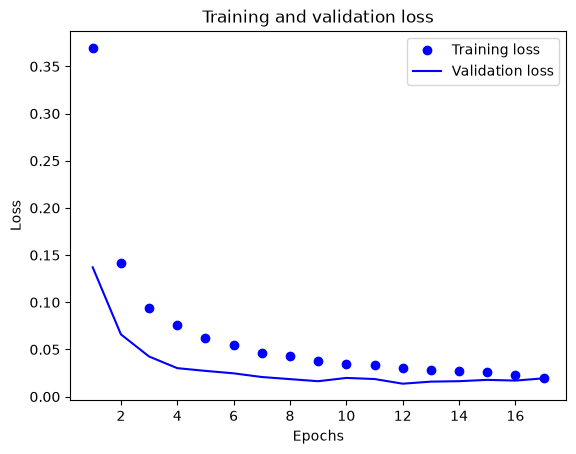

In [38]:
acc = history_dict["binary_accuracy"]
val_acc = history_dict["val_binary_accuracy"]
loss = history_dict["loss"]
val_loss = history_dict["val_loss"]

epochs = range(1, len(acc) + 1)

# "bo" = points bleus
plt.plot(epochs, loss, "bo", label="Training loss")
# "b" = ligne bleue
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()

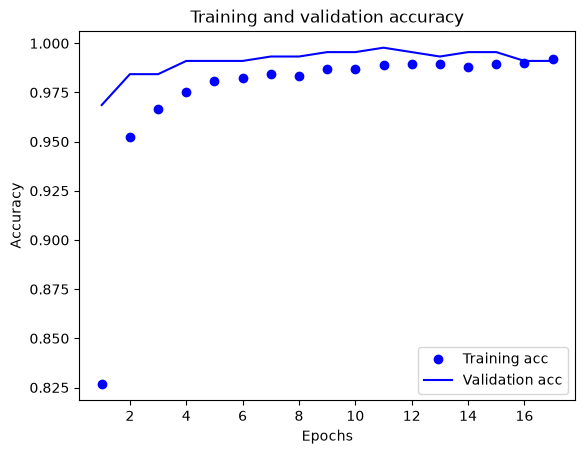

In [23]:
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")

plt.show()

##  Comprendre les courbes

Sur les graphiques :
- Les **points** représentent la loss et l'accuracy d'**entraînement**.
- Les **lignes** représentent la loss et l'accuracy de **validation**.

###  Observations
 La loss d'entraînement diminue et l'accuracy augmente, c'est normal : l'optimisation par descente de gradient minimise la perte.

 Si la validation cesse de s'améliorer pendant que l'entraînement continue, c'est un signe de **surapprentissage**.



#  Export du modèle

Dans le code ci-dessus, les couches de prétraitement sont **déjà intégrées** au modèle. Le modèle accepte donc directement les **valeurs brutes** d'un étudiant.

Nous sauvegardons le modèle au format `.keras`, puis nous le rechargeons pour vérifier qu'il donne les mêmes résultats.

In [25]:
model.save("modele_depression.keras")

export_model = tf.keras.models.load_model("modele_depression.keras")
export_model.compile(
    loss=losses.BinaryCrossentropy(from_logits=False), optimizer="adam", metrics=["accuracy"]
)

# Test avec raw_test_ds, qui contient des valeurs brutes
metrics = export_model.evaluate(raw_test_ds, return_dict=True)
print(metrics)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9866 - loss: 0.0345 
{'accuracy': 0.9865771532058716, 'loss': 0.03448713198304176}


##  Inférence sur de nouvelles données

Pour prédire sur de **nouveaux étudiants**, on appelle simplement `predict` avec des valeurs brutes. Les trois profils ci-dessous sont **inventés**, uniquement pour illustrer. Le résultat est une **probabilité** (entre 0 et 1).

In [26]:
def profil(**kw):
    base = {
        "Gender": "Female", "Age": 21, "Family_background": "Middle class",
        "Relationship_status": "Single", "Marital_status": "Unmarried",
        "Living_style": "Bachelor", "Current_semester": 4, "CGPA": 3.4,
        "friend_circle": "Yes", "Health_condition": "Normal",
        "Cost_without_study": 12000, "Home_division": "Dhaka",
    }
    base.update(kw)
    return base

exemples = [
    profil(Health_condition="Good"),
    profil(Health_condition="Abnormal"),
    profil(Health_condition="Critical"),
]

entree = {}
for c in colonnes_num:
    entree[c] = tf.constant([[float(e[c])] for e in exemples], dtype=tf.float32)
for c in colonnes_cat:
    entree[c] = tf.constant([[str(e[c])] for e in exemples])

probas = export_model.predict(entree).ravel()
for e, p in zip(exemples, probas):
    print(e["Health_condition"], "→ probabilité de dépression :", round(float(p), 3))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step
Good → probabilité de dépression : 0.0
Abnormal → probabilité de dépression : 1.0
Critical → probabilité de dépression : 1.0
